In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import json
import math
from matplotlib.pyplot import cm

plt.style.use('seaborn-v0_8') # I personally prefer seaborn for the graph style, but you may choose whichever you want.
params = {"ytick.color" : "black",
          "xtick.color" : "black",
          "axes.labelcolor" : "black",
          "axes.edgecolor" : "black",
          "text.usetex" : True,
          "font.family" : "serif",
          "font.serif" : ["Computer Modern Serif"]}
plt.rcParams.update(params)

output_dir = "/Users/russell/projects/stencil_research/cpu_attention_suite/plots"

In [27]:
results_dirs = [
    "/Users/russell/projects/stencil_research/cpu_attention_suite/results/size_sweep",
]

plot_data = {}
for n in ["fa2", "rec", "standard"]:
    plot_data[n] = {}

def load_results_file(path):
    with open(json_path, 'r') as json_file:
        data = json.load(json_file)
        n = data["n"]
        name = data["name"]
        time = np.average(data["times"]) / 1000.0
        plot_data[name][n] = time;
        
for results_dir in results_dirs:  
    for file in sorted(os.listdir(results_dir)):
        json_path = f"{results_dir}/{file}"
        load_results_file(json_path)

fa2_ns = sorted(plot_data["fa2"].keys())
fa2_times = [plot_data["fa2"][n] for n in fa2_ns]

rec_ns = sorted(plot_data["rec"].keys())
rec_times = [plot_data["rec"][n] for n in rec_ns]

standard_ns = sorted(plot_data["standard"].keys())
standard_times = [plot_data["standard"][n] for n in standard_ns]

speedup = np.array(fa2_times) / np.array(rec_times)

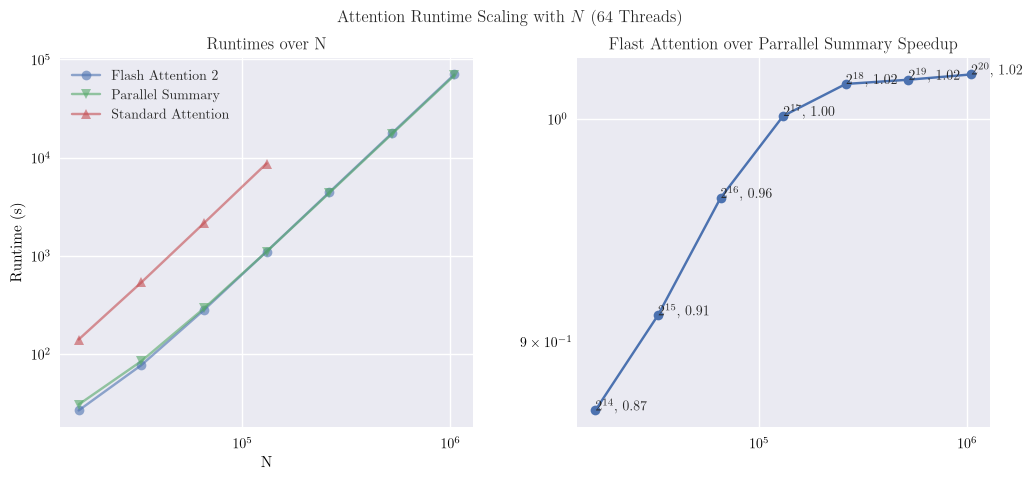

In [45]:
width = 12
height_ratio = 0.4
fig = plt.figure(figsize=(width, width * height_ratio))
n_rows = 1
n_cols = 2
width_ratios = [1.0, 1.0]
height_ratios = [1.0]
gs1 = fig.add_gridspec(
    n_rows, n_cols,
    width_ratios = width_ratios, 
    height_ratios = height_ratios,
    wspace = 0.25,
    hspace = 0.45,
)

ax_1 = fig.add_subplot(gs1[0, 0])
ax_1.plot(
    fa2_ns, 
    fa2_times,
    label="Flash Attention 2",
    marker='o',
    alpha=0.6,
)
ax_1.plot(
    rec_ns, 
    rec_times,
    label="Parallel Summary",
    marker="v",
    alpha=0.6,
)
ax_1.plot(
    standard_ns, 
    standard_times,
    label="Standard Attention",
    marker="^",
    alpha=0.6,
)    
ax_1.set_xticks(fa2_ns)
ax_1.set_ylabel("Runtime (s)")
ax_1.set_xlabel("N")
ax_1.legend()
ax_1.set_xscale('log')
ax_1.set_yscale('log')
ax_1.set_title("Runtimes over N")

ax_2 = fig.add_subplot(gs1[0, 1])
ax_2.plot(fa2_ns, speedup, marker = "o")
for i,j in zip(fa2_ns,speedup):
    p = int(math.log2(i));
    ax_2.annotate(f"$2^{{{p}}}$, {j:.2f}",xy=(i,j))
ax_2.set_xscale('log')
ax_2.set_yscale('log')
ax_2.set_title("Flast Attention over Parrallel Summary Speedup")

fig.suptitle("Attention Runtime Scaling with $N$ (64 Threads)")
plt.savefig(f"{output_dir}/size_sweep.pdf")

array([0.87107206, 0.91119133, 0.96325337, 1.00135817, 1.01664013,
       1.01867497, 1.02122592])

In [11]:
rec_times

[np.float64(30.530647599999998),
 np.float64(84.3961222),
 np.float64(290.9028594),
 np.float64(1101.6779474),
 np.float64(4355.9856882),
 np.float64(17349.402850000002),
 np.float64(68951.349972)]

In [12]:
standard_times

[np.float64(140.4020694),
 np.float64(535.0707804),
 np.float64(2149.516593),
 np.float64(8716.892770600001)]

In [13]:
70414.90585200001 / 68951.349972

1.0212259206033578